Eigenvalue energy
-0.9506519779945533 Last value: -3.5304987193578215e-13
-0.9506519779945533 Integral: 0.0005055948796460213
Non-eigenvalue energy
-0.8506519779945533 Last value: -0.01333811409593115
-0.8506519779945533 Integral: 0.00018231285453953526


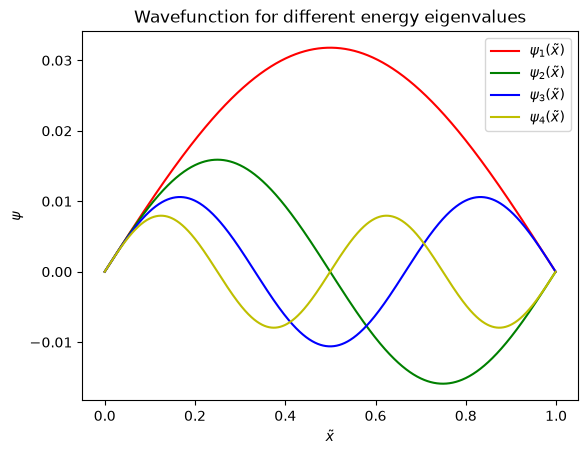

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.integrate
from scipy.integrate import simpson

# Plot normalized for report

L = 1
N = 1000
l = L/(N-1)
gamma2 = 200
x = np.linspace(0, L, N)
psi_0 = 0
psi_1 = 10**-4

def psi_eps(eps, x=x):
  k2 = [gamma2 * (eps + 1) for i in x]
  psi = [psi_0, psi_1]
  for i in range(1, N - 1):
    psi.append((2 * (1 - 5/12 * l**2 * k2[i]) * psi[i] -
     (1 + 1/12 * l**2 * k2[i-1]) * psi[i-1]) / (1 + 1/12
     * l**2 * k2[i+1]))
  return psi

print("Eigenvalue energy")
eps = np.pi**2 / gamma2 - 1
print(eps, "Last value:", psi_eps(eps)[N-1])
print(eps, "Integral:", simpson([i**2 for i in psi_eps(eps)], x))

print("Non-eigenvalue energy")
eps += 0.1
print(eps, "Last value:", psi_eps(eps)[N-1])
print(eps, "Integral:", simpson([i**2 for i in psi_eps(eps)], x))


colors = ["r", "g", "b", "y"]
for i in range(1, 5):
  eps = i**2 * np.pi**2 / gamma2 - 1
  plt.plot(np.arange(0, 1, 10**-3), psi_eps(eps), colors[i-1], label=r"$\psi_{}(\tilde x)$".format(i))
plt.legend()
plt.title("Wavefunction for different energy eigenvalues")
plt.xlabel(r"$\tilde x$")
plt.ylabel(r"$\psi$")
plt.show()

In [3]:
def find_eps(eps_0, acc=10**-6):
  eps = eps_0
  delta_eps = 0.04
  while abs(delta_eps) >= acc:
    prev_eps = eps
    eps += delta_eps
    if psi_eps(prev_eps)[N-1] * psi_eps(eps)[N-1] < 0:
      delta_eps /= -2
  return eps

prev_start = -1
eigenstates = []
for i in range(1, 11):
  eigenstates.append(find_eps(prev_start))
  print("Eigenvalues", i, ":", eigenstates[-1])
  print("Analytic Value", i**2 * np.pi**2 / gamma2 - 1, "\n")
  prev_start = find_eps(prev_start) + 1 / gamma2


Eigenvalues 1 : -0.9506530761718752
Analytic Value -0.9506519779945533 

Eigenvalues 2 : -0.8026086425781254
Analytic Value -0.8026079119782128 

Eigenvalues 3 : -0.5558679199218753
Analytic Value -0.5558678019509788 

Eigenvalues 4 : -0.21043212890625046
Analytic Value -0.2104316479128514 

Eigenvalues 5 : 0.23369995117187456
Analytic Value 0.23370055013616975 

Eigenvalues 6 : 0.7765283203124995
Analytic Value 0.7765287921960846 

Eigenvalues 7 : 1.4180529785156253
Analytic Value 1.4180530782668925 

Eigenvalues 8 : 2.158272705078125
Analytic Value 2.1582734083485944 

Eigenvalues 9 : 2.997188720703125
Analytic Value 2.99718978244119 

Eigenvalues 10 : 3.9348010253906254
Analytic Value 3.934802200544679 



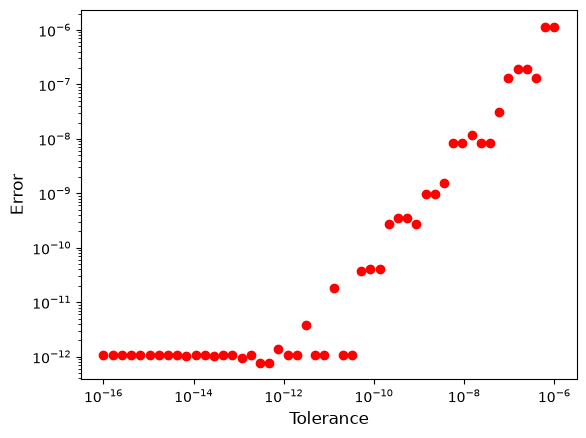

In [15]:
errors = []
accs = np.logspace(-6, -16)
for i in accs:
  errors.append(abs(find_eps(-1, i) / (np.pi**2 / gamma2 - 1) - 1))
plt.loglog()
plt.plot(accs, errors, "ro")
plt.ylabel("Error", size=12)
plt.xlabel("Tolerance", size=12)
#plt.title(r"Error over Accuracy of first energy eigenvalue $\epsilon_1$")
plt.savefig("Eigenstate 1 error over accuracy.pdf", bbox_inches="tight")
plt.show()

In [5]:
def norm_psi(eps, x=x):
  factor = np.sqrt(simpson([i**2 for i in psi_eps(eps)], x=x))
  return [i / factor for i in psi_eps(eps)]

epsilon = find_eps(-1, 1)
print(simpson([i**2 for i in psi_eps(epsilon)], x=x))
print(simpson([i**2 for i in norm_psi(epsilon)], x=x))

0.0033266700000001087
1.0000000000000002


Eigenstate 1: uncertainty = 0.5678615706442212
Eigenstate 2: uncertainty = 1.6702870383134563
Eigenstate 3: uncertainty = 2.627194566871052
Eigenstate 4: uncertainty = 3.5579914210177135
Eigenstate 5: uncertainty = 4.478979340294547
Eigenstate 6: uncertainty = 5.395177093040048
Eigenstate 7: uncertainty = 6.308664824683507
Eigenstate 8: uncertainty = 7.220463733602805
Eigenstate 9: uncertainty = 8.13113435633927
Eigenstate 10: uncertainty = 9.041009877589387


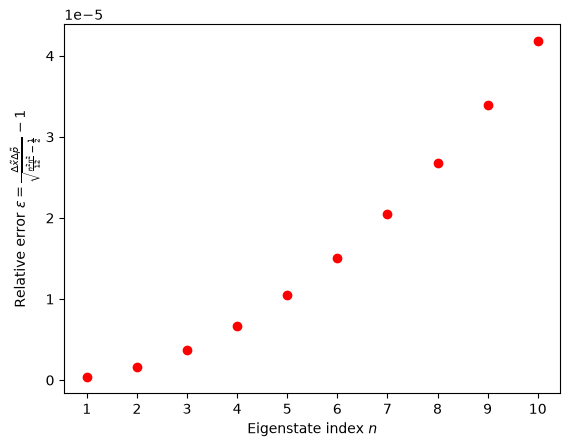

In [6]:
def stdev_x(psi, x=x):
    mean  = simpson(x * psi**2, x=x)
    mean2 = simpson(x**2 * psi**2, x=x)
    return np.sqrt(mean2 - mean**2)

def stdev_p(psi, x=x):
    l = x[1] - x[0]
    d2psi = (psi[:-2] - 2*psi[1:-1] + psi[2:]) / l**2
    return np.sqrt(-simpson(psi[1:-1] * d2psi, x=x[1:-1]))

uncertainties = []
for i in range(len(eigenstates)):
  uncertainties.append(stdev_x(np.array(norm_psi(eigenstates[i])), x) * stdev_p(np.array(norm_psi(eigenstates[i])), x))
  print("Eigenstate {}: uncertainty = {}".format(i + 1, uncertainties[-1]))

an_unc = [np.sqrt((i**2 * np.pi**2)/12 - 1/2) for i in range(1, 11)]
errors = [np.abs(i/j - 1) for (i, j) in zip(uncertainties, an_unc)]
plt.plot(range(1, 11), errors, "ro")
plt.xlabel(r"Eigenstate index $n$")
plt.ylabel(r"Relative error $\epsilon = \frac{\Delta \tilde x \Delta \tilde p}{\sqrt{\frac{n^2 \pi^2}{12} - \frac{1}{2}}} - 1$")
plt.xticks(np.array(range(1, 11)))
plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.show()

Eigenvalue 1: -0.9105575561523437
Uncertainty 1: 0.500087842070418

Eigenvalue 2: -0.7316729736328124
Uncertainty 2: 1.500016701127368

Eigenvalue 3: -0.5527868652343748
Uncertainty 3: 2.4999615351394575

Eigenvalue 4: -0.3738992309570311
Uncertainty 4: 3.499939695365529

Eigenvalue 5: -0.1949978637695311
Uncertainty 5: 4.499983645484405

Eigenvalue 6: -0.016011047363281097
Uncertainty 6: 5.500484763324288

Eigenvalue 7: 0.16337707519531267
Uncertainty 7: 6.503048732644661

Eigenvalue 8: 0.3441644287109377
Uncertainty 8: 7.511679443601523

Eigenvalue 9: 0.5286901855468752
Uncertainty 9: 8.530687270569597

Eigenvalue 10: 0.7208743286132815
Uncertainty 10: 9.554934111379172



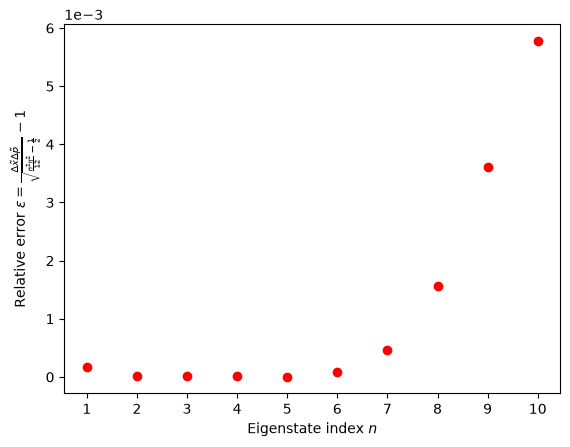

In [7]:
gamma2prime = 1000
def psi_eps_prime(eps, x=x):
  k2 = [gamma2prime * (eps - 8 * (i - 0.5)**2 + 1) for i in x]
  psi = [psi_0, psi_1]
  for i in range(1, N - 1):
    psi.append((2 * (1 - 5/12 * l**2 * k2[i]) * psi[i] - (1 + 1/12 * l**2 * k2[i-1]) * psi[i-1]) / (1 + 1/12 * l**2 * k2[i+1]))
  return psi

def find_eps_prime(eps_0, acc=10**-6):
  eps = eps_0
  delta_eps = 0.05
  while abs(delta_eps) >= acc:
    prev_eps = eps
    eps += delta_eps
    if psi_eps_prime(prev_eps)[N-1] * psi_eps_prime(eps)[N-1] < 0:
      delta_eps /= -2
  return eps

def norm_psi_prime(eps, x=x):
  factor = np.sqrt(simpson([i**2 for i in psi_eps_prime(eps)], x=x))
  return [i / factor for i in psi_eps_prime(eps)]

prev_start = -1
eigenstates = []
for i in range(1, 11):
  eigenstates.append(find_eps_prime(prev_start))
  prev_start = find_eps_prime(prev_start) + 1 / gamma2

uncertainties = []
for i in range(len(eigenstates)):
  uncertainties.append(stdev_x(np.array(norm_psi_prime(eigenstates[i]))) * stdev_p(np.array(norm_psi_prime(eigenstates[i]))))

for i in range(1, 11):
  print("Eigenvalue {}: {}".format(i, eigenstates[i - 1]))
  print("Uncertainty {}: {}\n".format(i, uncertainties[i - 1]))

an_unc = [i - 1/2 for i in range(1, 11)]
errors = [np.abs(i/j - 1) for (i, j) in zip(uncertainties, an_unc)]
plt.plot(range(1, 11), errors, "ro")
plt.xlabel(r"Eigenstate index $n$")
plt.ylabel(r"Relative error $\epsilon = \frac{\Delta \tilde x \Delta \tilde p}{\sqrt{\frac{n^2 \pi^2}{12} - \frac{1}{2}}} - 1$")
plt.xticks(np.array(range(1, 11)))
plt.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.show()

In [8]:
def gen_eigenstates(n):
  prev_start = -1
  egs = []
  for i in range(1, n + 1):
    egs.append(find_eps_prime(prev_start))
    prev_start = find_eps_prime(prev_start) + 1 / gamma2
  return egs

n = 100
diffs = []
for i, j in zip(gen_eigenstates(n), gen_eigenstates(n+1)[1::]):
  diffs.append(j - i)

slope = 0.9919


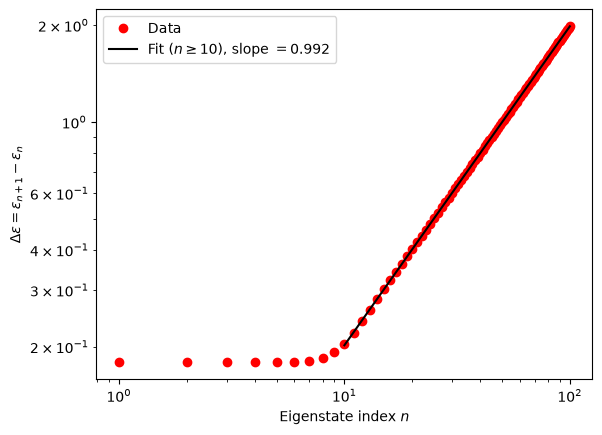

In [14]:
ns = np.arange(1, n + 1)
mask = ns >= 10

slope, intercept = np.polyfit(np.log10(ns[mask]), np.log10(np.array(diffs)[mask]), 1)
print(f"slope = {slope:.4f}")

plt.loglog()
plt.plot(ns, diffs, "ro", label="Data")
plt.plot(ns[mask], 10**intercept * ns[mask]**slope, "k-", label=rf"Fit ($n \geq 10$), slope $= {slope:.3f}$")
plt.xlabel(r"Eigenstate index $n$")
plt.ylabel(r"$\Delta \epsilon = \epsilon_{n+1} - \epsilon_{n}$")
plt.legend()
plt.savefig("Eigenstate energy differences.pdf", bbox_inches="tight")
plt.show()

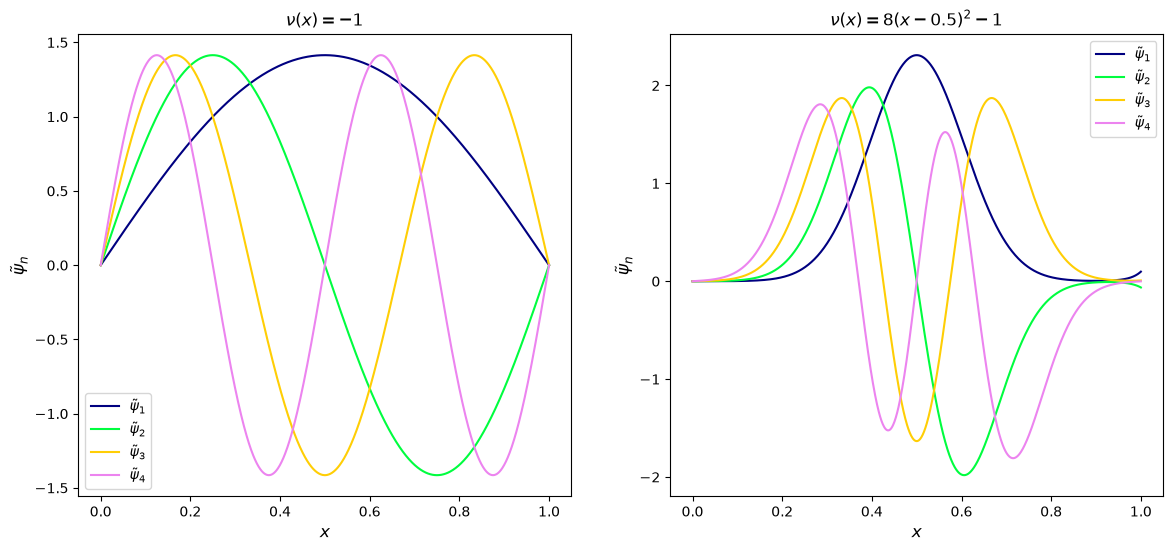

In [13]:
def normalize(psi, x=x):
  factor = np.sqrt(simpson([i**2 for i in psi], x=x))
  return [i / factor for i in psi]

n_states = 4

eigenstates_well = []
prev = -1
for i in range(n_states):
  e = find_eps(prev)
  eigenstates_well.append(e)
  prev = e + 1/gamma2

from cycler import cycler
xs = np.linspace(0, L, N)
plt.rcParams["axes.prop_cycle"] = cycler(color=plt.cm.gist_ncar(np.linspace(0, 0.9, n_states)))

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.title(r"$\nu(x) = -1$")
for i in range(n_states):
  plt.plot(xs, normalize(psi_eps(eigenstates_well[i])), label=rf"$\tilde \psi_{{{i+1}}}$")
plt.xlabel(r"$x$", size=12)
plt.ylabel(r"$\tilde \psi_n$", size=12)
plt.legend()
#plt.show()
plt.subplot(1, 2, 2)
plt.title(r"$\nu(x) = 8(x - 0.5)^2 - 1$")
for i in range(n_states):
  plt.plot(xs, normalize(psi_eps_prime(eigenstates[i])), label=rf"$\tilde \psi_{{{i+1}}}$")
plt.xlabel(r"$x$", size=12)
plt.ylabel(r"$\tilde \psi_n$", size=12)
plt.legend()
plt.savefig("Normalized wave functions.pdf", bbox_inches="tight")
plt.show()

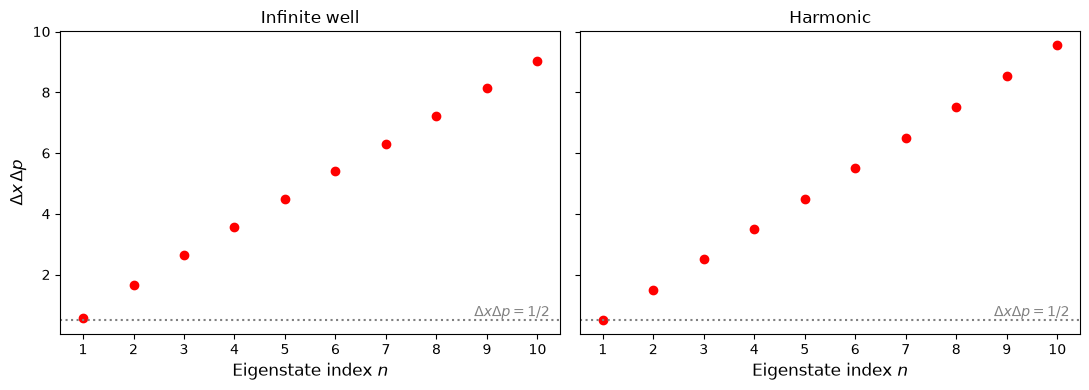

In [30]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, num, title in zip(axs, [unc_well, unc_harm], [r"Infinite well", r"Harmonic"]):
    ax.plot(n_idx, num, "ro")
    ax.axhline(0.5, color="gray", ls=":")
    ax.text(0.98, 0.5, r"$\Delta x \Delta p = 1/2$", color="gray", ha="right", va="bottom", transform=ax.get_yaxis_transform(), size=10)
    ax.set_xlabel(r"Eigenstate index $n$", size=12)
    ax.set_xticks(n_idx)
    ax.set_title(title, size=12)
axs[0].set_ylabel(r"$\Delta x\, \Delta p$", size=12)
plt.tight_layout()
plt.savefig("Uncertainty plots.pdf", bbox_inches="tight")
plt.show()